# Notebook 1 — EMO-FAR on Amazon Reviews 2023 (text + image, fairness)

**Goal of this notebook (execution demo):**
1. Build a clean, balanced 3-class product-review dataset from **Amazon Reviews 2023** (Fashion + Beauty), keeping only reviews that have a **customer photo**.
2. Compare text models:
   - **R1 Conventional** — classic cleaning (lowercase, remove stop-words, emojis, punctuation) + RoBERTa
   - **R2 Raw** — RoBERTa on the raw review text (honest modern baseline)
   - **R3 ECCM** — RoBERTa + our **Emotion-Consistent Context Modeling** (negation scope, intensifiers, contrast, informal cues, domain anchoring)
   - **R4 ECCM + Group-DRO** — the same, trained with a **trainable fairness objective** across product categories
3. **R5 ECCM + Group-DRO + Image** — adds the customer photo (CLIP patch features) with **token-level cross-attention**, **masked gating** and **modality dropout**.
4. Evaluate: accuracy, macro-F1, per-category F1, worst-group F1, fairness gap, calibration (ECE), F1 on reviews that contain negation, and robustness when images are missing.
5. A **live demo box**: type any review → prediction + highlighted emotion cues.

**Runtime:** Colab → Runtime → Change runtime type → **GPU (L4 or A100)**. Run the cells **top to bottom**.

## 0. Setup — mount Drive, check GPU, install the demo library

In [1]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
TEST_MODE = os.environ.get("EMOFAR_TEST") == "1"   # only used when the notebook is tested outside Colab

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    !pip install -q gradio

import torch, warnings
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()                      # hide long model-loading reports
warnings.filterwarnings("ignore", category=UserWarning)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "no GPU (training will be slow)")

Mounted at /content/drive
Device: cuda | NVIDIA L4


## 1. Settings
Change numbers here only. `N_PER_CLASS_PER_CAT = 2000` gives 2 categories × 3 classes × 2000 = **12,000 reviews**.

In [2]:
DATA_DIR = "/content/drive/MyDrive/datasets/Amazon-Reviews-2023/raw/review_categories"
OUT_DIR  = "/content/drive/MyDrive/emofar_results"          # results (CSV, plots) are saved here
CATEGORIES = ["Amazon_Fashion", "All_Beauty"]                # the two fairness groups

MODEL_NAME = "roberta-base"
CLIP_NAME  = "openai/clip-vit-base-patch32"
N_PER_CLASS_PER_CAT = 2000
MAX_LEN    = 128          # max sub-word tokens per review
EPOCHS     = 2
BATCH_SIZE = 32
LR_ENCODER = 2e-5         # learning rate for the pretrained RoBERTa weights
LR_NEW     = 1e-4         # learning rate for our new layers (ECCM, fusion, classifier)
SEEDS      = [42]         # use [42, 43, 44] for the final report (mean ± std)
GDRO_ETA   = 0.01         # Group-DRO step size
IMG_DROPOUT = 0.3         # modality dropout: chance of hiding the image during training
USE_IMAGES = True         # set False to skip the image part (R5)

if TEST_MODE:             # tiny settings used only to test this notebook on a CPU
    DATA_DIR, OUT_DIR = os.environ["EMOFAR_DATA"], os.environ["EMOFAR_OUT"]
    MODEL_NAME, MAX_LEN, BATCH_SIZE = "distilroberta-base", 64, 16
    N_PER_CLASS_PER_CAT = int(os.environ.get("EMOFAR_N", 40)); EPOCHS = int(os.environ.get("EMOFAR_EPOCHS", 1))

os.makedirs(OUT_DIR, exist_ok=True)
LABELS = ["negative", "neutral", "positive"]

## 2. Load reviews that have a customer photo
Labels from stars: **1–2★ → negative, 3★ → neutral, 4–5★ → positive**.
Lines with `"images": []` (no photo) are skipped before parsing, which makes loading fast.

In [3]:
import json, re, random, hashlib
import numpy as np, pandas as pd

def star_to_label(stars):
    return 0 if stars <= 2 else (1 if stars == 3 else 2)

rows = []
for cat in CATEGORIES:
    path = f"{DATA_DIR}/{cat}.jsonl"
    n_cat = 0
    with open(path, encoding="utf8") as f:
        for line in f:
            if '"images": []' in line:          # fast skip: review has no photo
                continue
            r = json.loads(line)
            if not r.get("images"):
                continue
            text = f"{r.get('title', '').strip()}. {r.get('text', '').strip()}".strip(". ").strip()
            if len(text.split()) < 3:
                continue
            rows.append({"text": text, "label": star_to_label(int(r["rating"])), "stars": int(r["rating"]),
                         "category": cat, "parent_asin": r["parent_asin"],
                         "image_url": r["images"][0].get("small_image_url", "")})
            n_cat += 1
    print(f"{cat}: {n_cat:,} reviews with photos")

df_all = pd.DataFrame(rows)
print("Total:", len(df_all))
print(pd.crosstab(df_all.category, df_all.label.map(dict(enumerate(LABELS)))))

Amazon_Fashion: 158,765 reviews with photos
All_Beauty: 59,357 reviews with photos
Total: 218122
label           negative  neutral  positive
category                                   
All_Beauty         11335     3912     44110
Amazon_Fashion     33224    12017    113524


## 3. Remove duplicates, balance the classes, split **by product**
- **Duplicates:** the same text appearing twice could land in both train and test (leakage).
- **Balance:** equal reviews per class and category, so the model cannot win by always saying "positive".
- **Product split:** all reviews of one product (`parent_asin`) go to the same split, so the test set contains **unseen products**.

In [4]:
def norm_key(t):
    return hashlib.md5(re.sub(r"\s+", " ", t.lower()).strip().encode()).hexdigest()

df_all["key"] = df_all.text.map(norm_key)
before = len(df_all)
df_all = df_all.drop_duplicates("key").reset_index(drop=True)
print(f"Removed {before - len(df_all):,} duplicate reviews")

parts = []
for cat in CATEGORIES:
    for lab in range(3):
        sub = df_all[(df_all.category == cat) & (df_all.label == lab)]
        n = min(N_PER_CLASS_PER_CAT, len(sub))
        parts.append(sub.sample(n=n, random_state=42))
df = pd.concat(parts).reset_index(drop=True)

rng = np.random.RandomState(42)
products = np.array(sorted(df.parent_asin.unique()), dtype=object)
rng.shuffle(products)
n_p = len(products)
split_of = {p: "train" for p in products[: int(0.70 * n_p)]}
split_of.update({p: "valid" for p in products[int(0.70 * n_p): int(0.85 * n_p)]})
split_of.update({p: "test" for p in products[int(0.85 * n_p):]})
df["split"] = df.parent_asin.map(split_of)

print(pd.crosstab([df.split, df.category], df.label.map(dict(enumerate(LABELS)))))
del df_all, rows                                  # free memory: the full table is no longer needed
import gc; gc.collect()
assert not (set(df[df.split == "train"].parent_asin) & set(df[df.split == "test"].parent_asin)), "product leak!"
print("Check passed: no product appears in both train and test.")

Removed 2,869 duplicate reviews
label                 negative  neutral  positive
split category                                   
test  All_Beauty           303      311       343
      Amazon_Fashion       285      306       285
train All_Beauty          1382     1385      1363
      Amazon_Fashion      1422     1402      1413
valid All_Beauty           315      304       294
      Amazon_Fashion       293      292       302
Check passed: no product appears in both train and test.


## 4. ECCM — Emotion-Consistent Context Modeling
For every word we compute **5 cue flags**:

| Flag | Meaning | Example |
|---|---|---|
| NEG | negation word | not, never, don't |
| SCOPE | word under a negation (next ≤3 words, stops at punctuation / "but") | not **very good** |
| INT | intensifier | very, so, extremely |
| CON | contrast word | but, however |
| INF | informal cue | 😡, sooo, !!!, AWFUL |

We **keep** every word (no stop-word removal) and only shorten stretched letters ("sooooo" → "soo", flagged as informal).
Inside the model, each RoBERTa word embedding is changed as: `e' = e × a × s + Σ flag_k · E_k`
- `s = 1 + α_INT·INT + α_INF·INF` (intensity weight, α learnable)
- `a = 1 + β·PMI(word, category)` (domain anchoring, β learnable)
- `E_k` = a learnable vector per cue type.

In [5]:
NEGATIONS = {"not", "no", "never", "nothing", "nobody", "none", "neither", "nor", "cannot", "without",
             "hardly", "barely", "scarcely", "nowhere", "cant", "dont", "doesnt", "didnt", "isnt", "wasnt",
             "wont", "wouldnt", "shouldnt", "couldnt", "arent", "werent", "havent", "hasnt", "hadnt", "aint"}
INTENSIFIERS = {"very", "really", "so", "too", "extremely", "super", "totally", "absolutely", "highly",
                "completely", "incredibly", "quite", "truly", "most", "much", "way", "seriously",
                "terribly", "awfully", "insanely", "utterly", "especially", "particularly", "even"}
CONTRAST = {"but", "however", "although", "though", "yet", "except", "whereas", "nevertheless", "unfortunately"}
SCOPE_BREAK = set(".,!?;:") | CONTRAST
EMOJI_RE = re.compile("[\U0001F300-\U0001FAFF\U00002600-\U000027BF\U0001F000-\U0001F2FF]")
WORD_RE = re.compile(r"\w+(?:'\w+)?|[^\w\s]")
FLAG_NAMES = ["NEG", "SCOPE", "INT", "CON", "INF"]

def eccm_words(text):
    """Split text into words and compute the 5 cue flags for each word."""
    words, flags = [], []
    for w in WORD_RE.findall(text):
        informal = bool(EMOJI_RE.search(w)) or bool(re.search(r"(\w)\1{2,}", w)) \
                   or (w.isupper() and len(w) >= 3 and w.isalpha()) or w == "!"
        w_norm = re.sub(r"(\w)\1{2,}", r"\1\1", w)                    # sooooo -> soo
        low = w_norm.lower().replace("'", "")
        f = [0, 0, 0, 0, 0]
        f[0] = int(low in NEGATIONS or w_norm.lower().endswith("n't"))
        f[2] = int(low in INTENSIFIERS)
        f[3] = int(low in CONTRAST)
        f[4] = int(informal)
        words.append(w_norm); flags.append(f)
    scope_left = 0                                                     # negation scope: next <=3 words
    for i, w in enumerate(words):
        if flags[i][0]:
            scope_left = 3; continue
        if w.lower() in SCOPE_BREAK:
            scope_left = 0; continue
        if scope_left > 0:
            flags[i][1] = 1; scope_left -= 1
    return words, flags

w, f = eccm_words("Not very good, but the colour is sooooo NICE 😍!!")
for word, fl in zip(w, f):
    print(f"{word:8s}", [n for n, v in zip(FLAG_NAMES, fl) if v])

Not      ['NEG']
very     ['SCOPE', 'INT']
good     ['SCOPE']
,        []
but      ['CON']
the      []
colour   []
is       []
soo      ['INF']
NICE     ['INF']
😍        ['INF']
!        ['INF']
!        ['INF']


### Conventional preprocessing (the baseline the paper criticises)
Lowercase, remove URLs, emojis, punctuation and **stop-words** (scikit-learn's English list, which contains *not*, *no*, *never*).

In [6]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
print("Is 'not' a stop-word?", "not" in ENGLISH_STOP_WORDS, "| 'never'?", "never" in ENGLISH_STOP_WORDS)

def conventional_clean(text):
    t = re.sub(r"https?://\S+", " ", text.lower())
    t = re.sub(r"[^a-z\s]", " ", t)                  # drops emojis, digits, punctuation, apostrophes
    return " ".join(w for w in t.split() if w not in ENGLISH_STOP_WORDS)

print(conventional_clean("Not very good, but the colour is sooooo NICE 😍!!"))

Is 'not' a stop-word? True | 'never'? True
good colour sooooo nice


### Domain anchoring: PMI of each word with each category (training data only)
**PMI** (pointwise mutual information) = how much more often a word appears in one category than overall.
Computed **only on the training split** to avoid leakage. Values are clipped to [0, 1] after dividing by 3.

In [7]:
from collections import Counter, defaultdict

df["eccm"] = df.text.map(eccm_words)
train_df = df[df.split == "train"]
word_cat, word_all, cat_total = defaultdict(Counter), Counter(), Counter()
for (words, _), cat in zip(train_df.eccm, train_df.category):
    for w_ in set(x.lower() for x in words):
        word_cat[cat][w_] += 1; word_all[w_] += 1
    cat_total[cat] += 1
N_TRAIN = len(train_df)

ANCHOR_SKIP = set(ENGLISH_STOP_WORDS) - NEGATIONS     # filler words are not domain words

def pmi(word, cat, min_count=10):
    c_all = word_all.get(word, 0)
    if c_all < min_count or not word.isalpha() or len(word) < 3 or word in ANCHOR_SKIP:
        return 0.0
    p_w_given_c = word_cat[cat].get(word, 0) / max(cat_total[cat], 1)
    p_w = c_all / N_TRAIN
    if p_w_given_c == 0:
        return 0.0
    return float(np.clip(np.log(p_w_given_c / p_w) / 3.0, 0.0, 1.0))

for cat in CATEGORIES:
    top = sorted(((pmi(w_, cat), w_) for w_ in word_cat[cat]), reverse=True)[:10]
    print(cat, "→", [w_ for _, w_ in top])

Amazon_Fashion → ['wallet', 'shorts', 'yoga', 'underwear', 'tummy', 'tights', 'swimsuit', 'sterling', 'sports', 'soles']
All_Beauty → ['waves', 'watery', 'tattoos', 'tangling', 'skincare', 'sheds', 'scents', 'puffiness', 'pores', 'pony']


## 5. Turn text into model inputs
RoBERTa splits words into **sub-word pieces**. `word_ids()` tells us which word each piece came from,
so every piece receives its word's cue flags and PMI value.

In [8]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, add_prefix_space=True)

def encode(frame, mode):
    """mode: 'conventional' | 'raw' | 'eccm'. Returns a dict of tensors."""
    ids, masks, flag_t, pmi_t = [], [], [], []
    for text, (words, flags), cat in zip(frame.text, frame.eccm, frame.category):
        if mode == "conventional":
            words = conventional_clean(text).split() or ["empty"]
            flags = [[0] * 5 for _ in words]
        elif mode == "raw":
            words = WORD_RE.findall(text); flags = [[0] * 5 for _ in words]
        enc = tokenizer(words, is_split_into_words=True, truncation=True, max_length=MAX_LEN,
                        padding="max_length")
        wid = enc.word_ids()
        fl = [[0] * 5 if i is None else flags[i] for i in wid]
        pm = [0.0 if (i is None or mode != "eccm") else pmi(words[i].lower(), cat) for i in wid]
        ids.append(enc["input_ids"]); masks.append(enc["attention_mask"]); flag_t.append(fl); pmi_t.append(pm)
    return {"input_ids": torch.tensor(ids), "attention_mask": torch.tensor(masks),
            "flags": torch.tensor(flag_t, dtype=torch.float), "pmi": torch.tensor(pmi_t, dtype=torch.float),
            "label": torch.tensor(frame.label.values), "group": torch.tensor([CATEGORIES.index(c) for c in frame.category]),
            "row": torch.tensor(frame.index.values)}

splits = {s: df[df.split == s] for s in ["train", "valid", "test"]}
encoded = {mode: {s: encode(fr, mode) for s, fr in splits.items()} for mode in ["conventional", "raw", "eccm"]}
print({s: len(fr) for s, fr in splits.items()})

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'train': 8367, 'valid': 1800, 'test': 1833}


## 6. (Optional) Customer photos → CLIP patch features
We download each review's first photo (256 px), then run the **frozen** CLIP vision encoder once.
CLIP gives **50 tokens per image** (1 summary + 49 patches), so text tokens can attend to real image regions.
A photo that fails to download is treated as a **missing modality** (`has_image = 0`).

In [9]:
IMG_FEATS, HAS_IMG = None, None
if USE_IMAGES:
    import requests, io
    from concurrent.futures import ThreadPoolExecutor
    from PIL import Image
    from transformers import CLIPVisionModel, CLIPImageProcessor

    def fetch(url):
        try:
            r = requests.get(url, timeout=10)
            r.raise_for_status()
            return Image.open(io.BytesIO(r.content)).convert("RGB")
        except Exception:
            return None

    clip_proc = CLIPImageProcessor.from_pretrained(CLIP_NAME)
    clip = CLIPVisionModel.from_pretrained(CLIP_NAME).to(DEVICE).eval()
    IMG_FEATS = np.zeros((len(df), 50, clip.config.hidden_size), dtype=np.float16)
    HAS_IMG = np.zeros(len(df), dtype=bool)
    urls = df.image_url.tolist()
    CHUNK = 256                       # download + encode 256 photos at a time (keeps memory low)
    with ThreadPoolExecutor(32) as pool, torch.no_grad():
        for start in range(0, len(urls), CHUNK):
            images = list(pool.map(fetch, urls[start:start + CHUNK]))
            ok = [i for i, im in enumerate(images) if im is not None]
            for b in range(0, len(ok), 64):
                sel = ok[b:b + 64]
                px = clip_proc(images=[images[i] for i in sel], return_tensors="pt")["pixel_values"].to(DEVICE)
                out = clip(pixel_values=px).last_hidden_state          # (batch, 50, 768)
                rows_ = [start + i for i in sel]
                IMG_FEATS[rows_] = out.float().cpu().numpy().astype(np.float16)
                HAS_IMG[rows_] = True
            if (start // CHUNK) % 10 == 0:
                print(f"  photos processed: {min(start + CHUNK, len(urls)):,} / {len(urls):,}")
    print(f"Downloaded and encoded {HAS_IMG.sum():,} / {len(urls):,} photos")
    del clip
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    print("Image features:", IMG_FEATS.shape)

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

  photos processed: 256 / 12,000
  photos processed: 2,816 / 12,000
  photos processed: 5,376 / 12,000
  photos processed: 7,936 / 12,000
  photos processed: 10,496 / 12,000
Downloaded and encoded 11,910 / 12,000 photos
Image features: (12000, 50, 768)


## 7. The model
- **Text encoder:** RoBERTa. With `use_eccm=True`, the embedding change from Section 4 is applied before RoBERTa.
- **Image branch (R5 only):** image patches → projection → **token-level cross-attention** (each text token looks at 50 image tokens).
- **Masked gating:** a small layer scores text vs image; a **missing image gets weight exactly 0** (score set to −∞ before softmax).
  This fixes the paper's Eq. 12, where softmax over sigmoids can never go below ≈0.16.

In [10]:
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModel

class EmoFarModel(nn.Module):
    def __init__(self, use_eccm=False, use_image=False, img_dim=768):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(MODEL_NAME)
        H = self.encoder.config.hidden_size
        self.use_eccm, self.use_image = use_eccm, use_image
        if use_eccm:
            self.cue_emb = nn.Parameter(torch.randn(5, H) * 0.02)      # E_k, one vector per cue type
            self.alpha = nn.Parameter(torch.tensor([0.1, 0.1]))          # α_INT, α_INF
            self.beta = nn.Parameter(torch.tensor(0.1))                  # β (domain anchoring)
        if use_image:
            self.img_proj = nn.Sequential(nn.Linear(img_dim, H), nn.LayerNorm(H))
            self.cross_attn = nn.MultiheadAttention(H, num_heads=8, batch_first=True)
            self.gate = nn.Linear(2 * H, 2)
        self.dropout = nn.Dropout(0.1)
        self.classifier = nn.Linear(H, 3)

    def forward(self, input_ids, attention_mask, flags, pmi, img=None, has_img=None, return_gate=False):
        emb = self.encoder.embeddings.word_embeddings(input_ids)        # (B, L, H)
        if self.use_eccm:
            s = 1 + self.alpha[0] * flags[..., 2] + self.alpha[1] * flags[..., 4]
            a = 1 + self.beta * pmi
            emb = emb * (a * s).unsqueeze(-1) + flags @ self.cue_emb
        tok = self.encoder(inputs_embeds=emb, attention_mask=attention_mask).last_hidden_state
        h_text = tok[:, 0]                                               # <s> token summary
        gate_w = None
        if self.use_image:
            v = self.img_proj(img)                                       # (B, 50, H)
            attended, _ = self.cross_attn(tok, v, v)                     # text tokens attend to image tokens
            m = attention_mask.unsqueeze(-1).float()
            h_img = (attended * m).sum(1) / m.sum(1).clamp(min=1)
            logits_g = self.gate(torch.cat([h_text, h_img], -1))
            logits_g = logits_g.masked_fill(torch.stack([torch.zeros_like(has_img), ~has_img], -1), float("-inf"))
            gate_w = logits_g.softmax(-1)                                # (B, 2): [w_text, w_image]
            h = gate_w[:, :1] * h_text + gate_w[:, 1:] * h_img
        else:
            h = h_text
        out = self.classifier(self.dropout(h))
        return (out, gate_w) if return_gate else out

## 8. Training and evaluation
- **Cross-entropy** (normal training) or **Group-DRO**: keeps a weight `q_g` per product category; the category with the
  higher loss gets more weight (`q_g ← q_g·exp(η·loss_g)`), so the model is pushed to improve its **worst** group.
  Unlike the paper's max−min F1 term, this is **differentiable**.
- **Metrics:** accuracy, macro-F1, per-category macro-F1, worst-group F1, gap, **ECE** (calibration, 15 bins),
  and macro-F1 on test reviews that contain a negation word.

In [11]:
import time
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
from transformers import get_linear_schedule_with_warmup

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def batches(data, bs, shuffle, seed=0):
    n = len(data["label"])
    order = np.random.RandomState(seed).permutation(n) if shuffle else np.arange(n)
    for i in range(0, n, bs):
        yield {k: v[order[i:i + bs]] for k, v in data.items()}

def model_inputs(b, use_image, drop_image_p=0.0, rng=None):
    x = {k: b[k].to(DEVICE) for k in ["input_ids", "attention_mask", "flags", "pmi"]}
    if use_image:
        rows = b["row"].numpy()
        has = HAS_IMG[rows].copy()
        if drop_image_p > 0:
            has &= rng.rand(len(has)) >= drop_image_p                   # modality dropout / missing-image test
        img = torch.tensor(IMG_FEATS[rows], dtype=torch.float).to(DEVICE)
        img = img * torch.tensor(has, dtype=torch.float, device=DEVICE)[:, None, None]
        x.update(img=img, has_img=torch.tensor(has, device=DEVICE))
    return x

def ece_score(probs, y, n_bins=15):
    conf, pred = probs.max(1), probs.argmax(1)
    ece, edges = 0.0, np.linspace(0, 1, n_bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        sel = (conf > lo) & (conf <= hi)
        if sel.any():
            ece += sel.mean() * abs((pred[sel] == y[sel]).mean() - conf[sel].mean())
    return float(ece)

@torch.no_grad()
def predict(model, data, use_image, drop_image_p=0.0, seed=0):
    model.eval(); probs = []
    rng = np.random.RandomState(seed)
    for b in batches(data, 64, False):
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=DEVICE == "cuda"):
            out = model(**model_inputs(b, use_image, drop_image_p, rng))
        probs.append(out.float().softmax(-1).cpu().numpy())
    return np.concatenate(probs)

def evaluate(probs, data):
    y, g, pred = data["label"].numpy(), data["group"].numpy(), probs.argmax(1)
    rows = data["row"].numpy()
    has_neg = np.array([any(f[0] for f in df.loc[r, "eccm"][1]) for r in rows])
    per_group = {CATEGORIES[k]: f1_score(y[g == k], pred[g == k], average="macro") for k in np.unique(g)}
    res = {"accuracy": accuracy_score(y, pred), "macro_f1": f1_score(y, pred, average="macro"),
           "worst_group_f1": min(per_group.values()), "fairness_gap": max(per_group.values()) - min(per_group.values()),
           "ece": ece_score(probs, y),
           "negation_f1": f1_score(y[has_neg], pred[has_neg], average="macro") if has_neg.any() else float("nan")}
    res.update({f"f1_{k}": v for k, v in per_group.items()})
    return res

def train_run(name, mode, use_eccm, loss_type, use_image, seed):
    set_seed(seed)
    data = encoded[mode]
    model = EmoFarModel(use_eccm=use_eccm, use_image=use_image).to(DEVICE)
    enc_params = list(model.encoder.parameters())
    enc_ids = {id(p) for p in enc_params}
    new_params = [p for p in model.parameters() if id(p) not in enc_ids]
    opt = torch.optim.AdamW([{"params": enc_params, "lr": LR_ENCODER}, {"params": new_params, "lr": LR_NEW}], weight_decay=0.01)
    steps = EPOCHS * int(np.ceil(len(data["train"]["label"]) / BATCH_SIZE))
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    scaler = torch.amp.GradScaler(enabled=DEVICE == "cuda")
    q = torch.ones(len(CATEGORIES), device=DEVICE) / len(CATEGORIES)    # Group-DRO weights
    rng = np.random.RandomState(seed)
    best_f1, best_state, t0 = -1, None, time.time()
    for ep in range(EPOCHS):
        model.train()
        for b in batches(data["train"], BATCH_SIZE, True, seed + ep):
            y, g = b["label"].to(DEVICE), b["group"].to(DEVICE)
            with torch.autocast(DEVICE, dtype=torch.float16, enabled=DEVICE == "cuda"):
                logits = model(**model_inputs(b, use_image, IMG_DROPOUT if use_image else 0.0, rng))
            per_sample = F.cross_entropy(logits.float(), y, reduction="none")
            if loss_type == "gdro":
                group_loss = torch.stack([per_sample[g == k].mean() if (g == k).any() else per_sample.new_zeros(())
                                          for k in range(len(CATEGORIES))])
                q = q * torch.exp(GDRO_ETA * group_loss.detach()); q = q / q.sum()
                loss = (q * group_loss).sum()
            else:
                loss = per_sample.mean()
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
        val = evaluate(predict(model, data["valid"], use_image), data["valid"])
        print(f"  [{name}] epoch {ep + 1}/{EPOCHS}  valid macro-F1 = {val['macro_f1']:.4f}  ({time.time() - t0:.0f}s)")
        if val["macro_f1"] > best_f1:
            best_f1 = val["macro_f1"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model

## 9. Run the experiments
Each run prints its validation macro-F1 after every epoch. The best epoch (by validation) is kept and tested once.

In [12]:
RUNS = [  # name, input mode, ECCM?, loss, image?
    ("R1 Conventional + RoBERTa", "conventional", False, "ce",   False),
    ("R2 Raw + RoBERTa",          "raw",          False, "ce",   False),
    ("R3 ECCM + RoBERTa",         "eccm",         True,  "ce",   False),
    ("R4 ECCM + Group-DRO",       "eccm",         True,  "gdro", False),
]
if USE_IMAGES:
    RUNS.append(("R5 ECCM + Group-DRO + Image", "eccm", True, "gdro", True))

results, models = [], {}
for name, mode, use_eccm, loss_type, use_image in RUNS:
    for seed in SEEDS:
        print(f"\n=== {name} | seed {seed} ===")
        model = train_run(name, mode, use_eccm, loss_type, use_image, seed)
        test = encoded[mode]["test"]
        res = evaluate(predict(model, test, use_image), test)
        res.update(run=name, seed=seed)
        results.append(res)
        if seed == SEEDS[0] and name.startswith(("R4", "R5")):   # keep only the models used below
            models[name] = model.cpu()
        del model; gc.collect()
        if DEVICE == "cuda":
            torch.cuda.empty_cache()

res_df = pd.DataFrame(results)
cols = ["accuracy", "macro_f1", "worst_group_f1", "fairness_gap", "ece", "negation_f1"] + [f"f1_{c}" for c in CATEGORIES]
summary = res_df.groupby("run", sort=False)[cols].agg(["mean", "std"]) if len(SEEDS) > 1 else res_df.set_index("run")[cols]
res_df.to_csv(f"{OUT_DIR}/amazon_results_all_seeds.csv", index=False)
summary.to_csv(f"{OUT_DIR}/amazon_results_summary.csv")
summary.round(4)


=== R1 Conventional + RoBERTa | seed 42 ===


model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

  [R1 Conventional + RoBERTa] epoch 1/2  valid macro-F1 = 0.7217  (35s)
  [R1 Conventional + RoBERTa] epoch 2/2  valid macro-F1 = 0.7372  (69s)

=== R2 Raw + RoBERTa | seed 42 ===


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

... (4 outputs left out)

  [R4 ECCM + Group-DRO] epoch 1/2  valid macro-F1 = 0.8000  (36s)
  [R4 ECCM + Group-DRO] epoch 2/2  valid macro-F1 = 0.8075  (71s)

=== R5 ECCM + Group-DRO + Image | seed 42 ===


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

  [R5 ECCM + Group-DRO + Image] epoch 1/2  valid macro-F1 = 0.7934  (37s)
  [R5 ECCM + Group-DRO + Image] epoch 2/2  valid macro-F1 = 0.8000  (75s)


,accuracy,macro_f1,worst_group_f1,fairness_gap,ece,negation_f1,f1_Amazon_Fashion,f1_All_Beauty
run,,,,,,,,
R1 Conventional + RoBERTa,0.7376,0.7352,0.7308,0.0068,0.0611,0.7062,0.7308,0.7376
R2 Raw + RoBERTa,0.8183,0.8169,0.7941,0.0434,0.0513,0.8026,0.7941,0.8375
R3 ECCM + RoBERTa,0.8167,0.8153,0.7926,0.0432,0.0457,0.8043,0.7926,0.8358
R4 ECCM + Group-DRO,0.8156,0.8141,0.7974,0.0316,0.0439,0.8008,0.7974,0.8290
R5 ECCM + Group-DRO + Image,0.8200,0.8184,0.8072,0.0208,0.0421,0.8049,0.8072,0.8280


## 10. Results chart

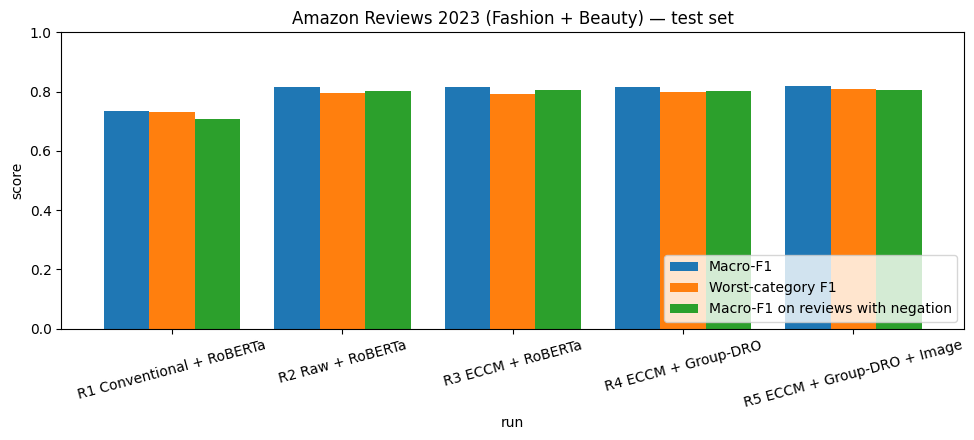

In [13]:
import matplotlib.pyplot as plt
plot_df = res_df.groupby("run", sort=False)[["macro_f1", "worst_group_f1", "negation_f1"]].mean()
ax = plot_df.plot.bar(figsize=(10, 4.5), rot=15, width=0.8)
ax.set_ylabel("score"); ax.set_ylim(0, 1); ax.set_title("Amazon Reviews 2023 (Fashion + Beauty) — test set")
ax.legend(["Macro-F1", "Worst-category F1", "Macro-F1 on reviews with negation"], loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/amazon_results.png", dpi=150); plt.show()

## 11. Robustness: what if photos are missing?
We hide the photo for 0 %, 30 %, 50 % and 70 % of test reviews and re-evaluate R5.
Because of **masked gating** and **modality dropout**, performance should degrade gracefully toward the text-only level.

In [14]:
if USE_IMAGES:
    r5 = models[RUNS[-1][0]].to(DEVICE)
    test = encoded["eccm"]["test"]
    rob = []
    for rate in [0.0, 0.3, 0.5, 0.7, 1.0]:
        m = evaluate(predict(r5, test, True, drop_image_p=rate, seed=7), test)
        rob.append({"missing_image_rate": rate, "macro_f1": m["macro_f1"], "accuracy": m["accuracy"]})
    rob_df = pd.DataFrame(rob)
    rob_df.to_csv(f"{OUT_DIR}/amazon_missing_image.csv", index=False)
    # gate check: average image weight with and without a photo
    b = next(batches(test, 64, False))
    with torch.no_grad():
        x = model_inputs(b, True, 0.0, np.random.RandomState(0))
        x["has_img"][: len(x["has_img"]) // 2] = False
        x["img"][: len(x["has_img"]) // 2] = 0
        _, gw = r5(**x, return_gate=True)
    half = len(gw) // 2
    print(f"Mean image weight — photo hidden: {gw[:half, 1].mean().item():.3f} | photo present: {gw[half:, 1].mean().item():.3f}")
    r5.cpu()
    display(rob_df.round(4)) if IN_COLAB else print(rob_df.round(4))

Mean image weight — photo hidden: 0.000 | photo present: 0.054


,missing_image_rate,macro_f1,accuracy
0,0.0,0.8184,0.8200
1,0.3,0.8183,0.8200
2,0.5,0.8177,0.8194
3,0.7,0.8182,0.8200
4,1.0,0.8177,0.8194


## 12. Live demo — type any review
Shows the predicted sentiment and highlights the ECCM cues:
<span style="background:#f8b4b4">negation</span>, <span style="background:#fde68a">negation scope</span>,
<span style="background:#bfdbfe">intensifier</span>, <span style="background:#ddd6fe">contrast</span>, <span style="background:#bbf7d0">informal</span>.

In [15]:
import html as _html
demo_model = models["R4 ECCM + Group-DRO"].to(DEVICE).eval()
COLORS = ["#f8b4b4", "#fde68a", "#bfdbfe", "#ddd6fe", "#bbf7d0"]

def analyse(review, category="Amazon_Fashion"):
    words, flags = eccm_words(review)
    frame = pd.DataFrame({"text": [review], "eccm": [(words, flags)], "category": [category], "label": [0]}, index=[-1])
    enc = encode(frame, "eccm")
    with torch.no_grad():
        p = demo_model(**{k: enc[k].to(DEVICE) for k in ["input_ids", "attention_mask", "flags", "pmi"]}).float().softmax(-1)[0].cpu().numpy()
    spans = []
    for w_, f_ in zip(words, flags):
        color = next((COLORS[k] for k in range(5) if f_[k]), None)
        t = _html.escape(w_)
        spans.append(f'<span style="background:{color};padding:1px 3px;border-radius:3px">{t}</span>' if color else t)
    return {LABELS[i]: float(p[i]) for i in range(3)}, " ".join(spans)

print(analyse("The fabric is not soft at all, but the colour is sooo pretty 😍"))

if IN_COLAB:
    import gradio as gr
    gr.Interface(fn=analyse,
                 inputs=[gr.Textbox(lines=3, label="Product review"), gr.Dropdown(CATEGORIES, value=CATEGORIES[0], label="Category")],
                 outputs=[gr.Label(label="Predicted sentiment"), gr.HTML(label="ECCM cues")],
                 title="EMO-FAR demo — emotion-preserving product-review sentiment",
                 examples=[["Not worth the money. Broke after two days 😡", "Amazon_Fashion"],
                           ["It's okay, nothing special but does the job.", "All_Beauty"],
                           ["Absolutely LOVE it!!! Fits perfectly", "Amazon_Fashion"]]).launch(share=True, debug=False)

({'negative': 0.005193373188376427, 'neutral': 0.20611141622066498, 'positive': 0.788695216178894}, 'The fabric is <span style="background:#f8b4b4;padding:1px 3px;border-radius:3px">not</span> <span style="background:#fde68a;padding:1px 3px;border-radius:3px">soft</span> <span style="background:#fde68a;padding:1px 3px;border-radius:3px">at</span> <span style="background:#fde68a;padding:1px 3px;border-radius:3px">all</span> , <span style="background:#ddd6fe;padding:1px 3px;border-radius:3px">but</span> the colour is <span style="background:#bbf7d0;padding:1px 3px;border-radius:3px">soo</span> pretty <span style="background:#bbf7d0;padding:1px 3px;border-radius:3px">😍</span>')
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e8cffd256314b8e789.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the 